# Fine-Tuning the Student with Unsloth

<b>Step 1: Imports and Constants</b>

In [2]:
from unsloth import FastLanguageModel
import torch
import os
import json
from pathlib import Path
from datasets import load_dataset, disable_caching
from trl import SFTTrainer, SFTConfig
from transformers import TrainingArguments
import matplotlib.pyplot as plt

ROOT_DIR = Path.cwd().parent
DATA_DIR = ROOT_DIR / "data"
TRAIN_JSONL = DATA_DIR / "distilled_train.jsonl"

OLLAMA_URL = "http://localhost:11434/api/generate"

🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.


c:\Users\thele\miniconda3\envs\ml_main\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1101 13:49:08.403000 38096 site-packages\torch\utils\_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W1101 13:49:08.473000 38096 site-packages\torch\utils\_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


Unsloth: xformers is installed but cannot load with torch 2.14.1+cu130 (it was built for 2.10.0+cu128), so PyTorch attention is used instead.
To install a matching xformers, run `unsloth install-kernels xformers`, or `pip uninstall xformers` to hide this. UNSLOTH_ENABLE_LOGGING=1 shows the full error.
🦥 Unsloth Zoo will now patch everything to make training faster!


<b>Step 2: Load the Pre-trained Student Model (Qwen 3.5 0.8B)

In [4]:
max_seq_length = 1024
load_in_4bit = False # Will be using original 16-bit precision because Qwen 3.5 0.8b is small anyways

model, tokenizer = FastLanguageModel.from_pretrained(
    model_name = "unsloth/Qwen3.5-0.8B",
    max_seq_length = max_seq_length,
    load_in_4bit = load_in_4bit,
    dtype = torch.bfloat16
)

==((====))==  Unsloth 2026.10.11: Fast Qwen3_5 patching. Transformers: 5.17.0.
   \\   /|    NVIDIA GeForce RTX 4070 SUPER. Num GPUs = 1. Max memory: 11.994 GB. Platform: Windows.
O^O/ \_/ \    Torch: 2.14.1+cu130. CUDA: 8.9. CUDA Toolkit: 13.0. Triton: 3.9.0
\        /    Bfloat16 = TRUE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!
Unsloth: QLoRA and full finetuning all not selected. Switching to 16bit LoRA.


Loading weights: 100%|██████████| 473/473 [00:00<00:00, 571.62it/s]


Unsloth: compiling each transformer block as one region (Qwen3_5DecoderLayer).


<b>Step 3: Attach the LoRA adapters</b>

In [5]:
model = FastLanguageModel.get_peft_model(
    model,
    r = 16,
    target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"],
    lora_alpha = 32,
    lora_dropout = 0,
    bias = "none",
    use_gradient_checkpoint = "unsloth",
    random_state = 42,
    use_rslora=False,
    loftq_config=None
)

Unsloth: Explicit target_modules are constrained by the finetune_(vision|language|attention|mlp) filters; adapters attach only where both select.


In [6]:
# Inspect LoRA's result

model.print_trainable_parameters()

trainable params: 6,389,760 || all params: 859,375,680 || trainable%: 0.7435


<b>Step 4: Load and Format the Distilled Dataset Generated by the Teacher</b>

In [7]:
dataset = load_dataset("json", data_files=str(TRAIN_JSONL), split="train")

def format_prompts(example):
    formatted_text = tokenizer.apply_chat_template(
        example["messages"],
        tokenize=False,
        add_generation_prompt=False,
        enable_thinking=False,
    )
    return {"text": formatted_text}

dataset = dataset.map(format_prompts, remove_columns=dataset.column_names)

print(f"Total rows: {len(dataset)}")
print(dataset[0]["text"])

Total rows: 1430
<|im_start|>system
You are a precise SQLite query generator. Given a database schema and a user question, output ONLY a valid SQLite query that answers the question. Do not include explanations.<|im_end|>
<|im_start|>user
Schema:
CREATE TABLE department (creation VARCHAR, department_id VARCHAR); CREATE TABLE management (department_id VARCHAR, head_id VARCHAR); CREATE TABLE head (head_id VARCHAR, born_state VARCHAR)

Question: What are the distinct creation years of the departments managed by a secretary born in state 'Alabama'?<|im_end|>
<|im_start|>assistant
<think>

</think>

SELECT DISTINCT d.creation FROM department d JOIN management m ON d.department_id = m.department_id JOIN head h ON m.head_id = h.head_id WHERE h.born_state = 'Alabama';<|im_end|>



<b>Step 5: Set Up the SFTTrainer</b>

In [8]:
# First force Hugging Face datasets & Unsloth to run single-threaded because Jupyter notebooks on Windows absolutely despise multi-processing for some reason
os.environ["UNSLOTH_NUM_PROC"] = "1"
os.environ["TOKENIZERS_PARALLELISM"] = "false"
disable_caching()

hyperparms = SFTConfig(
    per_device_train_batch_size=4,
    gradient_accumulation_steps=4,
    num_train_epochs=3,
    learning_rate=2e-4,
    lr_scheduler_type="cosine",
    warmup_steps = 0.05,
    bf16 = True,
    fp16 = False,
    optim = "adamw_8bit",
    dataset_text_field="text",
    max_seq_length=max_seq_length,
    dataset_num_proc=1, # Multi-processing doesn't seem to work in Jupyter notebooks
    packing=False,
    seed=42,
    logging_steps=10,
    output_dir = "outputs",
    save_strategy = "no",
    report_to = "none"
)

trainer = SFTTrainer(
    model=model,
    processing_class=tokenizer,
    train_dataset=dataset,
    args=hyperparms
)

`causal_conv1d_fn` is falling back to its reference PyTorch implementation because `causal_conv1d` is not installed. This is correct but much slower; install `causal_conv1d` for the optimized kernel.
Unsloth: Tokenizing ["text"]: 100%|██████████| 1430/1430 [00:00<00:00, 5018.94 examples/s]

🦥 Unsloth: Padding-free auto-enabled, enabling faster training.


<b>Step 6: Run the Training</b>

In [9]:
trainer_stats = trainer.train()

The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'eos_token_id': 248046}.


==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 1,430 | Num Epochs = 3 | Total steps = 270
O^O/ \_/ \    Batch size per device = 4 | Gradient accumulation steps = 4
\        /    Data Parallel GPUs = 1 | Total batch size (4 x 4 x 1) = 16
 "-____-"     Trainable parameters = 6,389,760 of 859,375,680 (0.74% trained)


Step,Training Loss
10,1.337696
20,0.707596
30,0.626589
40,0.588245
50,0.568409
60,0.548359
70,0.538148
80,0.515690
90,0.494537
100,0.442534


<b>Step 7: Inspect the Training Loss Curve</b>

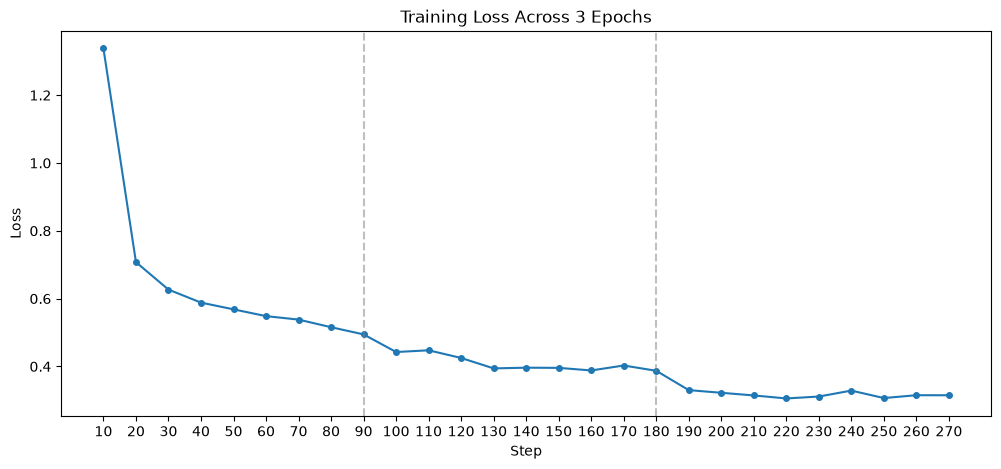

In [10]:
loss_history = [x for x in trainer.state.log_history if "loss" in x]

with open(DATA_DIR / "training_loss_log.json", "w", encoding="utf-8") as f:
            json.dump(loss_history, f)

# Plotting
X = [x["step"] for x in loss_history]
y = [x["loss"] for x in loss_history]

plt.figure(figsize=(12, 5))
plt.plot(X, y, marker="o", markersize=4)
plt.xticks(X)
plt.axvline(x=90, color="gray", linestyle="--", alpha=0.5)
plt.axvline(x=180, color="gray", linestyle="--", alpha=0.5)

plt.title("Training Loss Across 3 Epochs")
plt.xlabel("Step")
plt.ylabel("Loss")

plt.savefig(ROOT_DIR / "assets/training_loss_curve.png", dpi=300, bbox_inches="tight")
plt.show()

<b>Step 8: Exporting the Model for Ollama</b>

In [11]:
GGUF_DIR = ROOT_DIR / "models" / "qwen3.5-0.8b-sql-gguf"
model.save_pretrained_gguf(
    str(GGUF_DIR),
    tokenizer,
    quantization_method="f16",
)

Unsloth: Merging model weights to 16-bit format...


Unsloth: Restored added_tokens_decoder metadata in c:\Users\thele\OneDrive\Documents\Файлы\Everything\Uni\side projects\sql_distillation_qwen\models\qwen3.5-0.8b-sql-gguf\tokenizer_config.json.


Found HuggingFace hub cache directory: C:\Users\thele\.cache\huggingface\hub


Fetching 1 files: 100%|██████████| 1/1 [00:00<00:00,  4.83it/s]


Checking cache directory for required files...


Unsloth: Copying 1 files from cache to `c:\Users\thele\OneDrive\Documents\Файлы\Everything\Uni\side projects\sql_distillation_qwen\models\qwen3.5-0.8b-sql-gguf`: 100%|██████████| 1/1 [00:00<00:00,  1.61it/s]


... (2 outputs left out)

Unsloth: Merge process complete. Saved to `c:\Users\thele\OneDrive\Documents\Файлы\Everything\Uni\side projects\sql_distillation_qwen\models\qwen3.5-0.8b-sql-gguf`
Unsloth: Converting to GGUF format...
==((====))==  Unsloth: Conversion from HF to GGUF information
   \\   /|    [0] Installing llama.cpp might take 3 minutes.
O^O/ \_/ \    [1] Converting HF to GGUF f16 might take 3 minutes.
\        /    [2] Single-pass export: converting straight to ['f16'] - no separate quantize step.
 "-____-"     In total, you will have to wait at least 6 minutes.

Unsloth: Installing llama.cpp. This might take 3 minutes...
Unsloth: Installing prebuilt llama.cpp b11985-mix-c116c32 (app-b11985-mix-c116c32-windows-x64-cpu.zip) - skipping compilation.


[unsloth_zoo.llama_cpp|WARNING]Unsloth: Converter dependency install failed ([FAIL] Command `"c:\Users\thele\miniconda3\envs\ml_main\python.exe" -m pip install gguf protobuf sentencepiece mistral_common` failed with error `-------- ------------------------------- 2/9 [numpy]  WARNING: Failed to remove contents in a temporary directory 'C:\Users\thele\miniconda3\envs\ml_main\Lib\site-packages\~umpy.libs'.`
); conversion self-heals if needed.


Unsloth: Preparing converter script...
Unsloth: [1] Converting model into f16 GGUF format.
This might take 3 minutes...
Unsloth: Initial conversion completed! Files: ['c:\\Users\\thele\\OneDrive\\Documents\\Файлы\\Everything\\Uni\\side projects\\sql_distillation_qwen\\models\\qwen3.5-0.8b-sql-gguf_gguf\\Qwen3.5-0.8B.F16.gguf', 'c:\\Users\\thele\\OneDrive\\Documents\\Файлы\\Everything\\Uni\\side projects\\sql_distillation_qwen\\models\\qwen3.5-0.8b-sql-gguf_gguf\\Qwen3.5-0.8B.BF16-mmproj.gguf']
Unsloth: Model files cleanup...
Unsloth: All GGUF conversions completed successfully!
Generated files: ['c:\\Users\\thele\\OneDrive\\Documents\\Файлы\\Everything\\Uni\\side projects\\sql_distillation_qwen\\models\\qwen3.5-0.8b-sql-gguf_gguf\\Qwen3.5-0.8B.F16.gguf', 'c:\\Users\\thele\\OneDrive\\Documents\\Файлы\\Everything\\Uni\\side projects\\sql_distillation_qwen\\models\\qwen3.5-0.8b-sql-gguf_gguf\\Qwen3.5-0.8B.BF16-mmproj.gguf']
Unsloth: No Ollama template mapping found for model 'unsloth/Qwen

{'save_directory': 'c:\\Users\\thele\\OneDrive\\Documents\\Файлы\\Everything\\Uni\\side projects\\sql_distillation_qwen\\models\\qwen3.5-0.8b-sql-gguf',
 'gguf_directory': 'c:\\Users\\thele\\OneDrive\\Documents\\Файлы\\Everything\\Uni\\side projects\\sql_distillation_qwen\\models\\qwen3.5-0.8b-sql-gguf_gguf',
 'gguf_files': ['c:\\Users\\thele\\OneDrive\\Documents\\Файлы\\Everything\\Uni\\side projects\\sql_distillation_qwen\\models\\qwen3.5-0.8b-sql-gguf_gguf\\Qwen3.5-0.8B.F16.gguf',
  'c:\\Users\\thele\\OneDrive\\Documents\\Файлы\\Everything\\Uni\\side projects\\sql_distillation_qwen\\models\\qwen3.5-0.8b-sql-gguf_gguf\\Qwen3.5-0.8B.BF16-mmproj.gguf'],
 'modelfile_location': None,
 'want_full_precision': True,
 'is_vlm': True,
 'fix_bos_token': False}